# Data Cleaning on the Titanic Dataset
**Oasis Infobyte Internship | Data Analytics | Level 1 – Task 3: Cleaning Data**

**Author:** Poleboina Kavya

**Objective:** Take a raw passenger dataset, check its quality, and turn it into a clean, analysis-ready dataset. Every decision is explained.

**Dataset:** Titanic passenger data (`Titanic-Dataset.csv`, 891 rows x 12 columns), from Kaggle (M Yasser H, CC0 Public Domain).

**Steps:** 1. Load and inspect, 2. Data quality report, 3. Missing values, 4. Duplicates, 5. Standardisation, 6. Outliers, 7. Data types, 8. Before vs after, 9. Save

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Load and inspect the raw data

In [2]:
raw = pd.read_csv("Titanic-Dataset.csv")
df = raw.copy()          # we clean the copy and keep `raw` for the before-vs-after comparison
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 2. Data quality report
Before changing anything, we measure the problems: nulls, duplicates, data type issues and value ranges.

In [4]:
null_count = df.isnull().sum()
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulls": null_count,
    "null_%": (null_count / len(df) * 100).round(1),
    "unique_values": df.nunique(),
})
print("Duplicate rows (all columns):", df.duplicated().sum())
print("Duplicate PassengerId values:", df["PassengerId"].duplicated().sum())
quality

Duplicate rows (all columns): 0
Duplicate PassengerId values: 0


,dtype,nulls,null_%,unique_values
PassengerId,int64,0,0.0,891
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,str,0,0.0,891
Sex,str,0,0.0,2
Age,float64,177,19.9,88
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7
Ticket,str,0,0.0,681
Fare,float64,0,0.0,248


In [5]:
# Value range checks on numeric columns
df[["Age", "SibSp", "Parch", "Fare"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [6]:
# Look for formatting problems in text columns (extra spaces, inconsistent case)
for col in ["Sex", "Embarked"]:
    print(col, "->", df[col].value_counts(dropna=False).to_dict())

print("\nNames with leading/trailing spaces:", (df["Name"] != df["Name"].str.strip()).sum())
print("Fares equal to 0:", (df["Fare"] == 0).sum())

Sex -> {'male': 577, 'female': 314}
Embarked -> {'S': 644, 'C': 168, 'Q': 77, nan: 2}

Names with leading/trailing spaces: 2
Fares equal to 0: 15


### Data quality findings
- **Missing values:** 3 columns have gaps. **Age** is missing 177 values (19.9%), **Cabin** 687 (77.1%) and **Embarked** 2. The other 9 columns are complete.
- **Duplicates:** none. There are no duplicate rows and `PassengerId` is unique.
- **Formatting:** `Sex` is consistent (`male`/`female`), but **2 passenger names have leading or trailing spaces**.
- **Data types:** 5 of the 12 columns have a less suitable type. `PassengerId` is an integer but is really an identifier, `Survived` and `Pclass` are integers but are categories, and `Sex` and `Embarked` are plain text.
- **Value ranges:** Age runs from 0.42 (an infant) to 80, which is plausible. There are **15 passengers with a Fare of 0**. These may be crew, staff or free tickets, so we keep them rather than treat them as errors. The maximum Fare of 512 is far above the median of 14.45, which we deal with in the outlier step.

## 3. Handling missing values
| Column | Missing | Strategy | Why |
|---|---|---|---|
| **Age** | ~20% | Fill with the **median Age of the passenger's Pclass and Sex group** | Age is skewed and differs by class (first-class passengers were older), so a group median is more accurate than one overall mean. The median is not pulled by extreme ages. |
| **Embarked** | 2 rows | Fill with the **mode** (most common port) | It is a categorical column with only 2 gaps, and mode imputation is the standard choice. |
| **Cabin** | ~77% | **Drop the column**, but first create a `HasCabin` flag | Too much is missing to fill in reliably. The flag keeps the one useful signal, which is whether a cabin was recorded. |

In [7]:
# --- Age: median of each (Pclass, Sex) group ---
print("Median age by group:")
print(df.groupby(["Pclass", "Sex"])["Age"].median())

df["Age_was_missing"] = df["Age"].isnull()      # keep a record of which rows were imputed
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(lambda s: s.fillna(s.median()))

# --- Embarked: mode ---
embarked_mode = df["Embarked"].mode()[0]
print("\nMost common port:", embarked_mode)
df["Embarked"] = df["Embarked"].fillna(embarked_mode)

# --- Cabin: flag then drop ---
df["HasCabin"] = df["Cabin"].notnull().astype(int)
df = df.drop(columns=["Cabin"])

print("\nRemaining nulls:", df.isnull().sum().sum())

Median age by group:
Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64

Most common port: S

Remaining nulls: 0


## 4. Removing duplicates
We check for fully duplicated rows, and also for a repeated `PassengerId`, which should be unique.

In [8]:
rows_before = len(df)
dups = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Duplicate rows found: {dups}")
print(f"Rows removed: {rows_before - len(df)}  |  Rows remaining: {len(df)}")
print("Repeated PassengerId values:", df["PassengerId"].duplicated().sum())

Duplicate rows found: 0
Rows removed: 0  |  Rows remaining: 891
Repeated PassengerId values: 0


**Result:** the check found no duplicate rows, so none were removed. `PassengerId` is also unique. The step stays in the notebook because a cleaning workflow should always verify this.

## 5. Standardising formats
Text values are made consistent. These steps are safe even when the data is already tidy.
- Strip whitespace from all text columns (this fixes the 2 names found in the quality report).
- `Sex`: consistent capitalisation (`male`/`M`/`MALE` all become `Male`).
- `Embarked`: single-letter codes become full port names (C = Cherbourg, Q = Queenstown, S = Southampton).
- `Survived`: 0/1 gets a readable label column.

In [9]:
# Strip whitespace in every text column
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

# Sex: map every spelling variant to one standard value
sex_map = {"male": "Male", "m": "Male", "female": "Female", "f": "Female"}
df["Sex"] = df["Sex"].str.lower().map(sex_map)

# Embarked: codes -> full names
port_map = {"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"}
df["Embarked"] = df["Embarked"].str.upper().map(port_map)

# Survived: readable label (the 0/1 column is kept for analysis)
df["Survived_Label"] = df["Survived"].map({0: "Died", 1: "Survived"})

print(df["Sex"].value_counts(dropna=False).to_dict())
print(df["Embarked"].value_counts(dropna=False).to_dict())
print("Nulls introduced by mapping:", df[["Sex", "Embarked"]].isnull().sum().sum())

{'Male': 577, 'Female': 314}
{'Southampton': 646, 'Cherbourg': 168, 'Queenstown': 77}
Nulls introduced by mapping: 0


## 6. Outlier detection (IQR method)
A value is flagged as an outlier if it lies below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`.

In [10]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in ["Age", "Fare", "SibSp", "Parch"]:
    lo, hi = iqr_bounds(df[col])
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({"column": col, "lower_fence": round(lo, 2), "upper_fence": round(hi, 2),
                 "outliers": n_out, "outlier_%": round(n_out / len(df) * 100, 1),
                 "min": df[col].min(), "max": df[col].max()})
outlier_report = pd.DataFrame(rows).set_index("column")
outlier_report

,lower_fence,upper_fence,outliers,outlier_%,min,max
column,,,,,,
Age,-0.25,57.75,33,3.7,0.42,80.0000
Fare,-26.72,65.63,116,13.0,0.00,512.3292
SibSp,-1.50,2.50,46,5.2,0.00,8.0000
Parch,0.00,0.00,213,23.9,0.00,6.0000


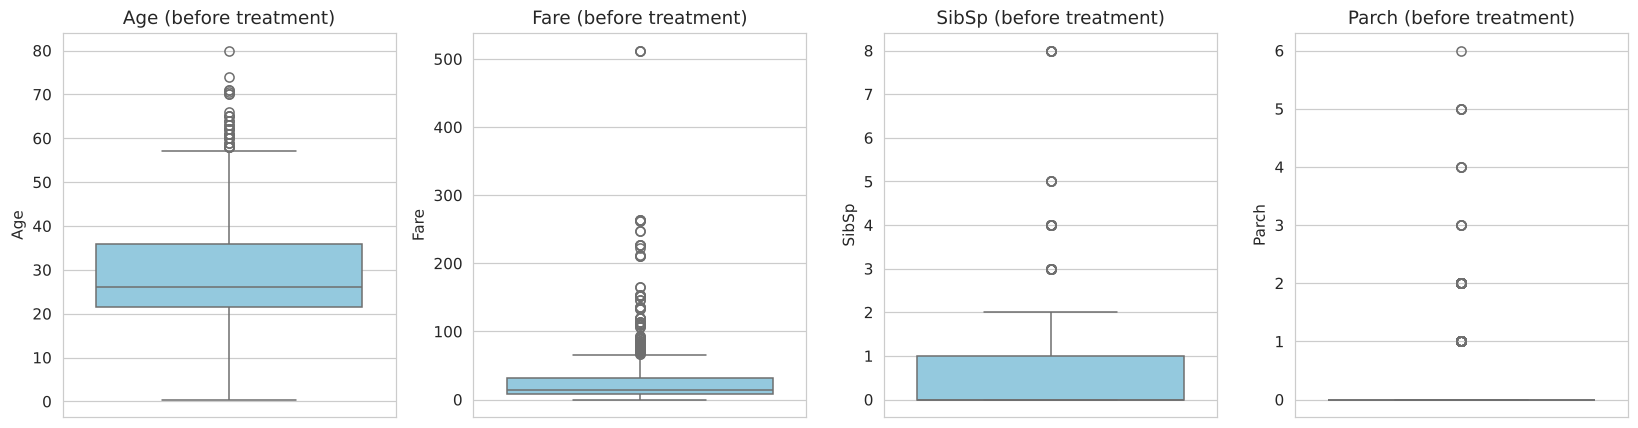

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "Fare", "SibSp", "Parch"]):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(f"{col} (before treatment)")
plt.tight_layout()
plt.show()

### Outlier decisions
| Column | Decision | Reason |
|---|---|---|
| **Age** | **Retain** | The flagged ages are real elderly passengers (the maximum is 80), which is plausible. |
| **SibSp / Parch** | **Retain** | Large families travelling together are genuine, not errors. For `Parch` the IQR is 0 (most passengers travelled with no parents or children), so both fences are 0 and every non-zero value gets flagged. That count of 213 is an artefact of the method, not a sign of bad data. |
| **Fare** | **Cap at the 99th percentile** (new column `Fare_capped`) | A few fares of 512 are far above the rest and would distort averages and models. Capping limits their pull while keeping every row. The original `Fare` is kept too. |

In [12]:
fare_cap = df["Fare"].quantile(0.99)
df["Fare_capped"] = df["Fare"].clip(upper=fare_cap)
print(f"99th percentile cap for Fare: {fare_cap:.2f}")
print("Rows capped:", (df["Fare"] > fare_cap).sum())
print("Max Fare before:", df["Fare"].max(), "| after capping:", df["Fare_capped"].max())

99th percentile cap for Fare: 249.01
Rows capped: 9
Max Fare before: 512.3292 | after capping: 249.00622000000035


## 7. Correcting data types
| Column | Correct type | Reason |
|---|---|---|
| PassengerId | string | It is an identifier. We never do arithmetic on it. |
| Survived, Pclass, Sex, Embarked | category | They hold a small set of fixed values. |
| Name, Ticket | string | Free text. |
| Age, Fare | float | Continuous numbers. |
| SibSp, Parch | int | Counts. |

In [13]:
df["PassengerId"] = df["PassengerId"].astype("string")
for col in ["Survived", "Pclass", "Sex", "Embarked", "Survived_Label"]:
    df[col] = df[col].astype("category")
df["Name"] = df["Name"].astype("string")
df["Ticket"] = df["Ticket"].astype("string")
df["Age"] = df["Age"].astype(float)
df["Fare"] = df["Fare"].astype(float)
df["SibSp"] = df["SibSp"].astype(int)
df["Parch"] = df["Parch"].astype(int)
df["Age_was_missing"] = df["Age_was_missing"].astype(bool)
df["HasCabin"] = df["HasCabin"].astype(int)

df.dtypes

PassengerId          string
Survived           category
Pclass             category
Name                 string
Sex                category
Age                 float64
SibSp                 int64
Parch                 int64
Ticket               string
Fare                float64
Embarked           category
Age_was_missing        bool
HasCabin              int64
Survived_Label     category
Fare_capped         float64
dtype: object

## 8. Before vs after summary

In [14]:
# What each column SHOULD be (same standard used for both the raw and the clean data)
expected = {"PassengerId": "text", "Survived": "category", "Pclass": "category", "Name": "text",
            "Sex": "category", "Age": "float", "SibSp": "int", "Parch": "int", "Ticket": "text",
            "Fare": "float", "Cabin": "text", "Embarked": "category"}

def kind(s):
    if isinstance(s.dtype, pd.CategoricalDtype): return "category"
    if pd.api.types.is_float_dtype(s): return "float"
    if pd.api.types.is_integer_dtype(s): return "int"
    return "text"

def dtype_accuracy(frame):
    cols = [c for c in expected if c in frame.columns]
    right = sum(kind(frame[c]) == expected[c] for c in cols)
    return f"{right}/{len(cols)} correct"

summary = pd.DataFrame({
    "Before (raw)": [raw.shape[0], raw.shape[1], raw.isnull().sum().sum(),
                     raw.duplicated().sum(), dtype_accuracy(raw)],
    "After (clean)": [df.shape[0], df.shape[1], df.isnull().sum().sum(),
                      df.duplicated().sum(), dtype_accuracy(df)],
}, index=["Row count", "Column count", "Total null values", "Duplicate rows", "Columns with a suitable dtype"])
summary

,Before (raw),After (clean)
Row count,891,891
Column count,12,15
Total null values,866,0
Duplicate rows,0,0
Columns with a suitable dtype,7/12 correct,11/11 correct


In [15]:
# Null count per column, before vs after
after_nulls = df.isnull().sum().reindex(raw.columns).astype(object)
after_nulls = after_nulls.where(after_nulls.notnull(), "column dropped")
pd.DataFrame({"Before": raw.isnull().sum(), "After": after_nulls})

,Before,After
PassengerId,0,0.0
Survived,0,0.0
Pclass,0,0.0
Name,0,0.0
Sex,0,0.0
Age,177,0.0
SibSp,0,0.0
Parch,0,0.0
Ticket,0,0.0
Fare,0,0.0


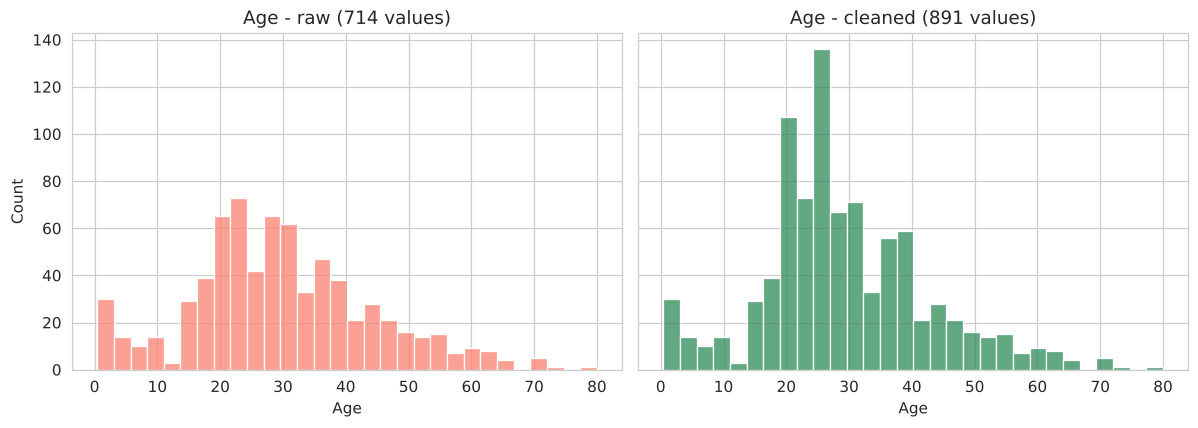

In [16]:
# Visual check: Age distribution before and after imputation
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.histplot(raw["Age"].dropna(), bins=30, ax=axes[0], color="salmon")
axes[0].set_title("Age - raw (714 values)")
sns.histplot(df["Age"], bins=30, ax=axes[1], color="seagreen")
axes[1].set_title("Age - cleaned (891 values)")
plt.tight_layout()
plt.show()

The imputed ages keep the same overall shape as the original distribution. There is a slightly taller bar near the group medians, which is the normal side effect of median imputation.

## 9. Save the cleaned dataset

In [17]:
final_cols = ["PassengerId", "Survived", "Survived_Label", "Pclass", "Name", "Sex", "Age",
              "Age_was_missing", "SibSp", "Parch", "Ticket", "Fare", "Fare_capped",
              "Embarked", "HasCabin"]
clean = df[final_cols]
clean.to_csv("Titanic_cleaned.csv", index=False)
print("Saved Titanic_cleaned.csv ->", clean.shape)
clean.head()

Saved Titanic_cleaned.csv -> (891, 15)


,PassengerId,Survived,Survived_Label,Pclass,Name,Sex,Age,Age_was_missing,SibSp,Parch,Ticket,Fare,Fare_capped,Embarked,HasCabin
0,1,0,Died,3,"Braund, Mr. Owen Harris",Male,22.0,False,1,0,A/5 21171,7.2500,7.2500,Southampton,0
1,2,1,Survived,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Female,38.0,False,1,0,PC 17599,71.2833,71.2833,Cherbourg,1
2,3,1,Survived,3,"Heikkinen, Miss. Laina",Female,26.0,False,0,0,STON/O2. 3101282,7.9250,7.9250,Southampton,0
3,4,1,Survived,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Female,35.0,False,1,0,113803,53.1000,53.1000,Southampton,1
4,5,0,Died,3,"Allen, Mr. William Henry",Male,35.0,False,0,0,373450,8.0500,8.0500,Southampton,0


## Summary of cleaning decisions
1. **Age** (177 missing): filled with the median age of each Pclass and Sex group. The flag `Age_was_missing` records which rows were filled.
2. **Embarked** (2 missing): filled with the most common port, Southampton.
3. **Cabin** (687 missing): dropped, and replaced by a `HasCabin` flag.
4. **Duplicates**: none found. Verified and documented.
5. **Standardisation**: whitespace stripped, `Sex` and `Embarked` made consistent, readable `Survived_Label` added.
6. **Outliers**: Age, SibSp and Parch retained because they are genuine. Fare capped at the 99th percentile in a new column.
7. **Data types**: IDs as text, categorical fields as category, numbers as float or int.
8. **Output**: `Titanic_cleaned.csv`, with no missing values and correct types.